# 1. Data Loading, Storage and File Formats
Problem Statement: Analyzing Sales Data from Multiple File Formats<br>
Dataset: Sales data in multiple file formats (e.g., CSV, Excel, JSON)<br>
Description: The goal is to load and analyze sales data from different file formats, including
CSV, Excel, and JSON, and perform data cleaning, transformation, and analysis on the
dataset.<br>
Tasks to Perform:<br>
Obtain sales data files in various formats, such as CSV, Excel, and JSON.<br>
1. Load the sales data from each file format into the appropriate data structures or
dataframes.<br>
2. Explore the structure and content of the loaded data, identifying any inconsistencies,
missing values, or data quality issues.<br>
3. Perform data cleaning operations, such as handling missing values, removing
duplicates, or correcting inconsistencies.<br>
4. Convert the data into a unified format, such as a common dataframe or data structure,
to enable seamless analysis.<br>
5. Perform data transformation tasks, such as merging multiple datasets, splitting
columns, or deriving new variables.<br>
6. Analyze the sales data by performing descriptive statistics, aggregating data by
specific variables, or calculating metrics such as total sales, average order value, or
product category distribution.<br>
7. Create visualizations, such as bar plots, pie charts, or box plots, to represent the sales
data and gain insights into sales trends, customer behavior, or product performance.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [5]:
csv = pd.read_csv("sales_data.csv")
print("CSV file of Sales Data")
csv.head()

CSV file of Sales Data


,Order_ID,Date,Product,Category,Quantity,Price,Customer,Region
0,1001,2026-01-05,Laptop,Electronics,2.0,60000,Amit,West
1,1002,2026-01-08,Mouse,Accessories,5.0,800,Rahul,North
2,1003,2026-01-12,Keyboard,Accessories,3.0,1500,Priya,South
3,1004,2026-01-18,Monitor,Electronics,2.0,12000,Sneha,West
4,1005,2026-02-03,Laptop,Electronics,1.0,60000,Amit,East


In [7]:
!python -m pip install openpyxl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [openpyxl]━━ 1/2 [openpyxl]


In [8]:
excel = pd.read_excel("sales_data.xlsx")
print("excel file:")
excel.head()

excel file:


,Order_ID,Date,Product,Category,Quantity,Price,Customer,Region
0,1001,2026-01-05,Laptop,Electronics,2.0,60000,Amit,West
1,1002,2026-01-08,Mouse,Accessories,5.0,800,Rahul,North
2,1003,2026-01-12,Keyboard,Accessories,3.0,1500,Priya,South
3,1004,2026-01-18,Monitor,Electronics,2.0,12000,Sneha,West
4,1005,2026-02-03,Laptop,Electronics,1.0,60000,Amit,East


In [9]:
json = pd.read_json("sales_data.json")
print("json data")
json.head()

json data


,Order_ID,Date,Product,Category,Quantity,Price,Customer,Region
0,1001,2026-01-05,Laptop,Electronics,2.0,60000,Amit,West
1,1002,2026-01-08,Mouse,Accessories,5.0,800,Rahul,North
2,1003,2026-01-12,Keyboard,Accessories,3.0,1500,Priya,South
3,1004,2026-01-18,Monitor,Electronics,2.0,12000,Sneha,West
4,1005,2026-02-03,Laptop,Electronics,1.0,60000,Amit,East


In [10]:
# 2. EXPLORE AND COMBINE DATA
df = pd.concat([csv,excel,json], ignore_index=True)

print("\nDataset Information:")
df.info()



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 45 entries, 0 to 44
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Order_ID  45 non-null     int64  
 1   Date      45 non-null     object 
 2   Product   45 non-null     str    
 3   Category  45 non-null     str    
 4   Quantity  42 non-null     float64
 5   Price     45 non-null     int64  
 6   Customer  42 non-null     str    
 7   Region    45 non-null     str    
dtypes: float64(1), int64(2), object(1), str(4)
memory usage: 2.9+ KB


In [11]:
df.isnull().sum()

Order_ID    0
Date        0
Product     0
Category    0
Quantity    3
Price       0
Customer    3
Region      0
dtype: int64

In [15]:
df = df.drop_duplicates()

In [16]:
df.shape

(28, 8)

In [17]:
df.describe()

,Order_ID,Quantity,Price
count,28.000000,26.000000,28.000000
mean,1007.500000,2.230769,20457.142857
std,4.105101,1.210213,25808.402717
min,1001.000000,1.000000,800.000000
25%,1004.000000,1.000000,1500.000000
50%,1007.500000,2.000000,7250.000000
75%,1011.000000,3.000000,60000.000000
max,1014.000000,5.000000,60000.000000


In [18]:
df

,Order_ID,Date,Product,Category,Quantity,Price,Customer,Region
0,1001,2026-01-05,Laptop,Electronics,2.0,60000,Amit,West
1,1002,2026-01-08,Mouse,Accessories,5.0,800,Rahul,North
2,1003,2026-01-12,Keyboard,Accessories,3.0,1500,Priya,South
3,1004,2026-01-18,Monitor,Electronics,2.0,12000,Sneha,West
4,1005,2026-02-03,Laptop,Electronics,1.0,60000,Amit,East
5,1006,2026-02-10,Mouse,Accessories,4.0,800,Rohan,North
6,1007,2026-02-15,Headphones,Accessories,3.0,2500,Neha,South
7,1008,2026-02-20,Monitor,Electronics,1.0,12000,Arjun,West
8,1009,2026-02-25,Keyboard,Accessories,2.0,1500,Priya,South
9,1010,2026-03-02,Laptop,Electronics,1.0,60000,Rahul,North


In [19]:
df.isnull().sum()

Order_ID    0
Date        0
Product     0
Category    0
Quantity    2
Price       0
Customer    2
Region      0
dtype: int64

In [22]:
# # 3. DATA CLEANING
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

In [24]:
df["Quantity"] = df["Quantity"].fillna(df["Quantity"].median())
df["Customer"] = df["Customer"].fillna(df["Customer"].mode()[0])

In [25]:
df

,Order_ID,Date,Product,Category,Quantity,Price,Customer,Region
0,1001,2026-01-05,Laptop,Electronics,2.0,60000,Amit,West
1,1002,2026-01-08,Mouse,Accessories,5.0,800,Rahul,North
2,1003,2026-01-12,Keyboard,Accessories,3.0,1500,Priya,South
3,1004,2026-01-18,Monitor,Electronics,2.0,12000,Sneha,West
4,1005,2026-02-03,Laptop,Electronics,1.0,60000,Amit,East
5,1006,2026-02-10,Mouse,Accessories,4.0,800,Rohan,North
6,1007,2026-02-15,Headphones,Accessories,3.0,2500,Neha,South
7,1008,2026-02-20,Monitor,Electronics,1.0,12000,Arjun,West
8,1009,2026-02-25,Keyboard,Accessories,2.0,1500,Priya,South
9,1010,2026-03-02,Laptop,Electronics,1.0,60000,Rahul,North


In [29]:
# 4. DATA TRANSFORMATION
df["Sales"] = df["Quantity"] * df["Price"]
df["Month"] = df["Date"].dt.month

print("\nCleaned Dataset:")
df.head()


Cleaned Dataset:


,Order_ID,Date,Product,Category,Quantity,Price,Customer,Region,Sales,Month
0,1001,2026-01-05,Laptop,Electronics,2.0,60000,Amit,West,120000.0,1
1,1002,2026-01-08,Mouse,Accessories,5.0,800,Rahul,North,4000.0,1
2,1003,2026-01-12,Keyboard,Accessories,3.0,1500,Priya,South,4500.0,1
3,1004,2026-01-18,Monitor,Electronics,2.0,12000,Sneha,West,24000.0,1
4,1005,2026-02-03,Laptop,Electronics,1.0,60000,Amit,East,60000.0,2


In [30]:
# 5. SALES ANALYSIS
print("\nTotal Sales:", df["Sales"].sum())

order_sales = df.groupby("Order_ID")["Sales"].sum()
print("Average Order Value:", order_sales.mean())

print("\nSales by Category:")
print(df.groupby("Category")["Sales"].sum())

print("\nSales by Region:")
print(df.groupby("Region")["Sales"].sum())


Total Sales: 777600.0
Average Order Value: 55542.857142857145

Sales by Category:
Category
Accessories     57600.0
Electronics    720000.0
Name: Sales, dtype: float64

Sales by Region:
Region
East     123200.0
North    134400.0
South     40000.0
West     480000.0
Name: Sales, dtype: float64


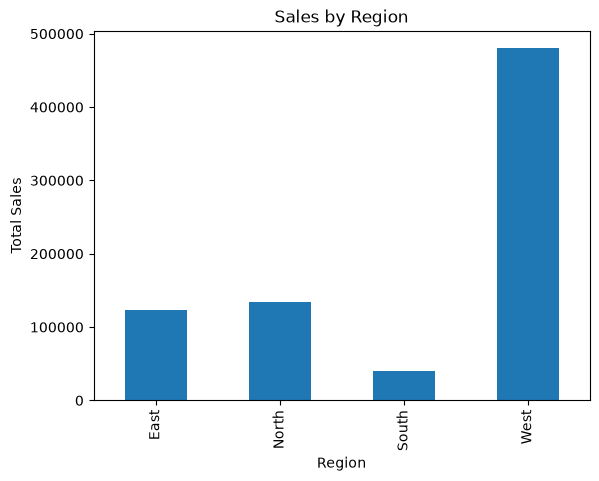

In [31]:
# 6. BAR CHART - SALES BY REGION
df.groupby("Region")["Sales"].sum().plot(kind="bar", title="Sales by Region")
plt.ylabel("Total Sales")
plt.show()

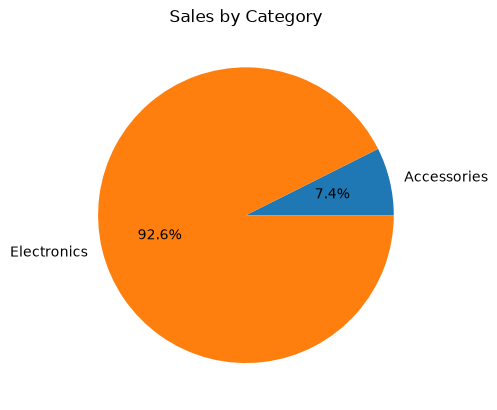

In [32]:
# 7. PIE CHART - SALES BY CATEGORY
df.groupby("Category")["Sales"].sum().plot(
    kind="pie", autopct="%1.1f%%",
    title="Sales by Category"
)
plt.ylabel("")
plt.show()

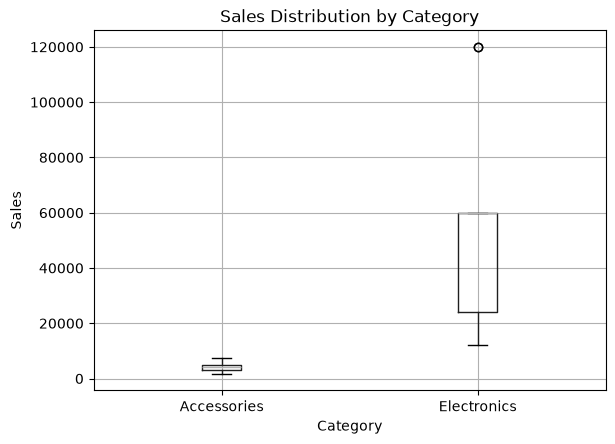

In [33]:
# 8. BOX PLOT - SALES DISTRIBUTION
df.boxplot(column="Sales", by="Category")
plt.title("Sales Distribution by Category")
plt.suptitle("")
plt.ylabel("Sales")
plt.show()